# 02. 공연과 상권 연결

**목적:** 고정 KOPIS 스냅샷의 공식 시설 ID·좌표와 01의 상권 격자로 300m·500m·800m 분기 공연 노출을 만든다. 공식 ID 연결과 이름 임시 연결을 구분한다.

공연 기간과 분기가 겹치는 등록 공연 ID 수이며 일별 회차·관객 수가 아니다. 현재 좌표와 경계를 과거 12분기에 공통 적용한다. 두 업종 패널은 연결 검증용이며 최종 회귀는 04의 10종 패널을 사용하는 05~06에서 수행한다. 입력 매니페스트는 `final/metadata/`, 산출물은 `data/analysis/final/`과 `reports/final/`이다. 네트워크 요청은 없다.

In [1]:
from pathlib import Path
import json
import hashlib
import os
from datetime import datetime, timezone
for name in ['OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'OMP_NUM_THREADS']:
    os.environ[name] = '1'
import sys
import platform
import importlib.metadata
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# 프로젝트 루트 또는 notebooks 폴더에서 실행할 수 있습니다.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/raw/seoul_sales').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('졸업프로젝트 폴더 또는 notebooks 폴더에서 실행하세요.')
RAW = ROOT / 'data/raw'
ANALYSIS = ROOT / 'data/analysis/final'
REPORTS = ROOT / 'reports/final'
FIGURES = REPORTS / 'figures'
for folder in [ANALYSIS, REPORTS, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 16)
pd.set_option('display.max_rows', 16)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')
YEARS = [2023, 2024, 2025]
DISTRICTS = {'11110': '종로구', '11440': '마포구'}
INDUSTRIES = {'CS100001': '한식음식점', 'CS100010': '커피-음료'}
KEY = ['quarter', 'area_id', 'industry_id']
print('프로젝트:', ROOT)
print('Python:', platform.python_version())


프로젝트: C:\Coding\졸업프로젝트
Python: 3.12.14


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

DISTRICT_COLORS = {'종로구': '#36688d', '마포구': '#d46b32'}
font_names = {font.name for font in fm.fontManager.ttflist}
font = next((name for name in ['Malgun Gothic', 'NanumGothic', 'AppleGothic'] if name in font_names), 'DejaVu Sans')
sns.set_theme(style='whitegrid', font=font, rc={'axes.unicode_minus': False})
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'font.size': 10})
path = ANALYSIS / 'sales_stores_panel.csv'
if not path.exists():
    raise FileNotFoundError('먼저 01_입력검증과_준비.ipynb를 실행하세요.')
panel = pd.read_csv(path, dtype={'quarter': str, 'area_id': str, 'industry_id': str})
# 저장 후 다시 읽어도 키와 미제공 매출의 구분이 유지되는지 검사합니다.
assert not panel.duplicated(KEY).any()
assert panel.loc[panel['availability'].isin(['sales_absent', 'both_absent']), 'total_sales'].isna().all()

def save_figure(fig, filename):
    for ax in fig.axes:
        legend = ax.get_legend()
        if legend is not None and legend.get_title().get_text() == 'district':
            legend.set_title('지역')
    fig.tight_layout()
    fig.savefig(FIGURES / filename, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('분석 패널:', len(panel), '행 / 상권:', panel['area_id'].nunique(), '개')


분석 패널: 3624 행 / 상권: 151 개


## 1. 공연과 시설을 연결하고 근거를 남기기

공연 상세의 공식 `mt10id`를 우선 사용합니다. 나머지는 시설명 완전 일치 또는 ‘시설명(홀명)’의 유일한 접두어 일치로 후보를 정합니다. 공백과 `(폐관)` 표시만 정리하며 비슷한 이름을 강제로 연결하지 않습니다.

`official_detail`만 공식 ID를 직접 확인한 행입니다. 나머지 이름 연결은 검증 대상입니다. 공식 ID와 이름 후보가 다르면 공식 ID를 채택하고 충돌 목록을 저장합니다. 공연 시작·종료일은 연구기간의 월별 목록을 유지하며 최신 상세 날짜와의 차이는 따로 감사합니다.


In [3]:
import unicodedata
from collections import defaultdict
KOPIS = ROOT / 'data/processed/kopis'
snapshot_pointer = ROOT / 'final/metadata/kopis_analysis_sources.json'
if not snapshot_pointer.exists():
    raise FileNotFoundError('final/metadata의 고정 KOPIS 입력 매니페스트가 필요합니다.')
collection_snapshot = json.loads(snapshot_pointer.read_text(encoding='utf-8'))
assert collection_snapshot.get('validated') is True, '수집 스냅샷의 검증 완료가 필요합니다.'
for record in collection_snapshot['input_sources']:
    assert hashlib.sha256((ROOT / record['path']).read_bytes()).hexdigest() == record['sha256']
kopis_paths = {
    'performances_list': KOPIS / 'performances_list_seoul_2023_2025.csv',
    'facilities_list': KOPIS / 'facilities_list_seoul.csv',
    'performance_candidates': KOPIS / 'performance_detail_candidates.csv',
    'facility_details': KOPIS / 'facilities_detail_seoul.csv',
    'performance_details': KOPIS / 'performances_detail_candidates_2023_2025.csv'}
for name in ['facility_details', 'performance_details']:
    record = collection_snapshot['files'][name]
    selected = ROOT / record['path']
    assert hashlib.sha256(selected.read_bytes()).hexdigest() == record['sha256']
    kopis_paths[name] = selected
manifest_inputs = {row['path'] for row in collection_snapshot['input_sources']}
assert all(kopis_paths[name].relative_to(ROOT).as_posix() in manifest_inputs
           for name in ['performances_list', 'facilities_list', 'performance_candidates'])
performances = pd.read_csv(kopis_paths['performances_list'], dtype=str)
facility_list = pd.read_csv(kopis_paths['facilities_list'], dtype=str)
facility_details = pd.read_csv(kopis_paths['facility_details'], dtype=str)
performance_details = pd.read_csv(kopis_paths['performance_details'], dtype=str)
performance_candidates = pd.read_csv(kopis_paths['performance_candidates'], dtype=str)
source_provenance = [{'role': name, 'path': path.relative_to(ROOT).as_posix(),
    'sha256': hashlib.sha256(path.read_bytes()).hexdigest(), 'bytes': path.stat().st_size}
    for name, path in kopis_paths.items()]
for name, frame in [('facility_details', facility_details), ('performance_details', performance_details)]:
    assert len(frame) == collection_snapshot['files'][name]['rows']
display(pd.DataFrame(source_provenance)[['role', 'path']])
for frame, key in [(performances, 'mt20id'), (facility_list, 'mt10id'),
                   (facility_details, 'mt10id'), (performance_details, 'mt20id')]:
    assert not frame[key].duplicated().any()

def normalize_name(value):
    return '' if pd.isna(value) else ''.join(unicodedata.normalize('NFKC', value).replace('(폐관)', '').split())
name_to_ids = defaultdict(set)
for row in facility_list.itertuples():
    name_to_ids[normalize_name(row.fcltynm)].add(row.mt10id)

def match_name(value):
    name = normalize_name(value)
    if not name:
        return pd.NA, 'unmatched'
    ids = name_to_ids.get(name, set())
    method = 'exact_unique_name'
    if not ids:
        prefixes = [key for key in name_to_ids if key and name.startswith(key + '(')]
        if prefixes:
            ids = name_to_ids[max(prefixes, key=len)]
        method = 'prefix_unique_name'
    if len(ids) == 1:
        return next(iter(ids)), method
    return pd.NA, 'ambiguous' if ids else 'unmatched'

matches = performances['fcltynm'].map(match_name)
performances['name_candidate_id'] = [value[0] for value in matches]
performances['link_method'] = [value[1] for value in matches]
performances['mt10id'] = performances['name_candidate_id'].astype('string')
official_ids = performance_details.set_index('mt20id')['mt10id']
performances['official_id'] = performances['mt20id'].map(official_ids).astype('string')
official = performances['official_id'].notna()
performances['name_official_conflict'] = (official & performances['name_candidate_id'].notna() &
    performances['official_id'].ne(performances['name_candidate_id'])).fillna(False)
performances.loc[official, 'mt10id'] = performances.loc[official, 'official_id']
performances.loc[official, 'link_method'] = 'official_detail'
performances['start_date'] = pd.to_datetime(performances['prfpdfrom'], format='%Y.%m.%d', errors='coerce')
performances['end_date'] = pd.to_datetime(performances['prfpdto'], format='%Y.%m.%d', errors='coerce')
performances['valid_period'] = performances['start_date'].notna() & performances['end_date'].ge(performances['start_date'])
link_summary = performances['link_method'].value_counts().rename_axis('link_method').reset_index(name='performance_ids')
display(link_summary)
print('공식 ID와 이름 후보 불일치:', int(performances['name_official_conflict'].sum()))
print('기간 해석 불가:', int((~performances['valid_period']).sum()))
link_summary.to_csv(REPORTS / 'performance_link_methods.csv', index=False, encoding='utf-8-sig')
performances.loc[performances['name_official_conflict'],
    ['mt20id', 'fcltynm', 'name_candidate_id', 'official_id', 'link_method']].to_csv(
    REPORTS / '03_official_name_conflicts.csv', index=False, encoding='utf-8-sig')


,role,path
0,performances_list,data/processed/kopis/performances_list_seoul_2...
1,facilities_list,data/processed/kopis/facilities_list_seoul.csv
2,performance_candidates,data/processed/kopis/performance_detail_candid...
3,facility_details,data/analysis/kopis_snapshots/20261004_154020_...
4,performance_details,data/analysis/kopis_snapshots/20261004_154020_...


,link_method,performance_ids
0,exact_unique_name,16320
1,official_detail,13727


공식 ID와 이름 후보 불일치: 0
기간 해석 불가: 0


### 수집 완료 범위와 공연 기간의 출처

시설 전체 목록, 공연 상세 수집 후보, 서울 전체 공연 목록을 다른 분모로 표시합니다. 공연 상세의 최신 시작·종료일은 2023~2025년 월별 목록과 별도로 비교하고, 기존 목록 기간으로 계산한 분기 노출을 유지합니다. 상세 날짜가 더 최신이라는 이유만으로 과거 분기 기간을 교체하지 않습니다.

In [4]:
candidate_ids = set(performance_candidates['mt20id'])
detail_ids = set(performance_details['mt20id'])
assert not performance_candidates['mt20id'].duplicated().any()
assert detail_ids.issubset(set(performances['mt20id']))
collection_coverage = pd.DataFrame([
    {'scope': '시설 전체 목록', 'eligible_ids': len(facility_list),
     'detail_ids': int(facility_list['mt10id'].isin(facility_details['mt10id']).sum())},
    {'scope': '공연 상세 수집 후보', 'eligible_ids': len(candidate_ids),
     'detail_ids': len(candidate_ids & detail_ids)},
    {'scope': '서울 전체 공연 목록', 'eligible_ids': len(performances),
     'detail_ids': int(official.sum())}])
collection_coverage['without_detail_ids'] = collection_coverage['eligible_ids'] - collection_coverage['detail_ids']
collection_coverage['detail_coverage_pct'] = 100 * collection_coverage['detail_ids'] / collection_coverage['eligible_ids']
collection_coverage.to_csv(REPORTS / '03_collection_coverage.csv', index=False, encoding='utf-8-sig')
display(collection_coverage)

period_comparison = performances[['mt20id', 'prfpdfrom', 'prfpdto']].merge(
    performance_details[['mt20id', 'prfpdfrom', 'prfpdto']], on='mt20id',
    suffixes=('_list', '_detail'), validate='one_to_one')
for source in ['list', 'detail']:
    for field in ['prfpdfrom', 'prfpdto']:
        period_comparison[f'{field}_{source}_date'] = pd.to_datetime(
            period_comparison[f'{field}_{source}'], format='%Y.%m.%d', errors='coerce')
period_comparison['period_differs'] = (
    period_comparison['prfpdfrom_list_date'].ne(period_comparison['prfpdfrom_detail_date']) |
    period_comparison['prfpdto_list_date'].ne(period_comparison['prfpdto_detail_date']))
period_comparison['quarter_membership_differs'] = False
for quarter in pd.period_range('2023Q1', '2025Q4', freq='Q'):
    membership = {source: (period_comparison[f'prfpdfrom_{source}_date'].le(quarter.end_time) &
        period_comparison[f'prfpdto_{source}_date'].ge(quarter.start_time)) for source in ['list', 'detail']}
    period_comparison['quarter_membership_differs'] |= membership['list'].ne(membership['detail'])
period_comparison.to_csv(REPORTS / '03_list_detail_period_comparison.csv', index=False, encoding='utf-8-sig')
display(period_comparison.loc[period_comparison['period_differs'],
    ['mt20id', 'prfpdfrom_list', 'prfpdto_list', 'prfpdfrom_detail', 'prfpdto_detail', 'quarter_membership_differs']].head(10))
display(Markdown(f"**해석:** 목록·상세의 기간 차이는 {period_comparison['period_differs'].sum():,}개, "
    f"2023~2025년 분기 포함 여부가 달라지는 공연은 {period_comparison['quarter_membership_differs'].sum():,}개다. "
    '이 차이는 기간 수정 이력을 뜻하며 과거 실제 공연 일정의 정답을 확정하지 않는다. 아래 노출에는 목록 기간만 사용한다.'))


,scope,eligible_ids,detail_ids,without_detail_ids,detail_coverage_pct
0,시설 전체 목록,1755,1755,0,100.000
1,공연 상세 수집 후보,13727,13727,0,100.000
2,서울 전체 공연 목록,30047,13727,16320,45.685


,mt20id,prfpdfrom_list,prfpdto_list,prfpdfrom_detail,prfpdto_detail,quarter_membership_differs


**해석:** 목록·상세의 기간 차이는 0개, 2023~2025년 분기 포함 여부가 달라지는 공연은 0개다. 이 차이는 기간 수정 이력을 뜻하며 과거 실제 공연 일정의 정답을 확정하지 않는다. 아래 노출에는 목록 기간만 사용한다.

## 2. 좌표 누락은 어느 정도인가?

시설 상세의 위도·경도를 숫자로 변환하고 범위를 확인합니다. 좌표 확보율은 현재 시설 목록 기준이며 과거 위치나 이전 이력을 검증한 것은 아닙니다. 좌표·기간 정보가 부족한 공연은 별도 파일로 남깁니다.


좌표 미수집을 실제 공연 부재로 해석하지 않는다. 수집한 상세 행 수와 유효 좌표를 가진 시설 수를 구분하며, 공식 공연 상세 ID와 이름 임시 연결도 별도 집계한다.

In [5]:
facility_details['longitude'] = pd.to_numeric(facility_details['lo'], errors='coerce')
facility_details['latitude'] = pd.to_numeric(facility_details['la'], errors='coerce')
facility_details['valid_coordinates'] = (facility_details['longitude'].between(124, 132) &
                                         facility_details['latitude'].between(33, 39))
facilities = facility_list.merge(facility_details[['mt10id', 'longitude', 'latitude', 'valid_coordinates', 'adres']],
                                on='mt10id', how='left', validate='one_to_one')
facilities['valid_coordinates'] = facilities['valid_coordinates'].eq(True)
coverage = facilities.groupby('gugunnm', observed=True).agg(
    listed=('mt10id', 'size'), with_coordinates=('valid_coordinates', 'sum'))
coverage['coverage_pct'] = coverage['with_coordinates'] / coverage['listed'] * 100
display(coverage.loc[['종로구', '마포구']])
performances = performances.merge(facilities[['mt10id', 'gugunnm', 'valid_coordinates']],
                                  on='mt10id', how='left', validate='many_to_one')
performances['valid_coordinates'] = performances['valid_coordinates'].eq(True)
performances.to_csv(ANALYSIS / 'performance_facility_linkage.csv', index=False, encoding='utf-8-sig')
unresolved = performances.loc[~performances['valid_coordinates'] | ~performances['valid_period']]
unresolved.to_csv(REPORTS / 'performances_unresolved_for_spatial_analysis.csv', index=False, encoding='utf-8-sig')
coverage.to_csv(REPORTS / 'facility_coordinate_coverage.csv', encoding='utf-8-sig')
print('공연 ID 중 좌표 연결 가능:', int(performances['valid_coordinates'].sum()), '/', len(performances))
target_linkage = performances.loc[performances['gugunnm'].isin(DISTRICTS.values())]
target_official_ids = int(target_linkage['link_method'].eq('official_detail').sum())
print('연구 지역 연결 공연 중 공식 ID:', target_official_ids, '/', len(target_linkage))


,listed,with_coordinates,coverage_pct
gugunnm,,,
종로구,376,376,100.000
마포구,296,296,100.000


공연 ID 중 좌표 연결 가능: 30047 / 30047
연구 지역 연결 공연 중 공식 ID: 11635 / 11635


## 3. 공연장 점과 상권 폴리곤의 최단거리

시설 좌표를 WGS84 경위도로 해석한 뒤 SHP의 미터 단위 좌표계로 투영합니다. **폴리곤까지의 최단거리**를 사용하며 내부 시설의 거리는 0m입니다.

유효하지 않은 도형은 거리 계산용 사본에 `make_valid`를 적용하고 기록합니다. 원본 파일은 바꾸지 않습니다. 현재 경계와 시설 위치를 모든 분기에 공통 적용하는 한계가 있습니다.


서울시의 2024년 공간단위 변경 공지가 있으므로, 재수집 파일이 기존 파일과 같아도 과거 분기 경계가 동일했다고 해석하지 않는다.

In [6]:
import shapefile
import shapely
from shapely.geometry import shape
from pyproj import CRS, Transformer

seoul_pointer = ROOT / 'final/metadata/seoul_analysis_sources.json'
seoul_snapshot = json.loads(seoul_pointer.read_text(encoding='utf-8'))
assert seoul_snapshot['status'] == 'validated' and seoul_snapshot['validation_passed']
area_source = next(item for item in seoul_snapshot['items'] if item['dataset'] == 'areas')
for entry in area_source['extracted']:
    assert hashlib.sha256((ROOT / entry['path']).read_bytes()).hexdigest() == entry['sha256']
boundary_path = ROOT / next(entry['path'] for entry in area_source['extracted'] if entry['path'].endswith('.shp'))
reader = shapefile.Reader(str(boundary_path), encoding=boundary_path.with_suffix('.cpg').read_text().strip())
projected_crs = CRS.from_wkt(boundary_path.with_suffix('.prj').read_text())
assert projected_crs.to_epsg() == 5181, '경계 좌표계 변경: 검토 후 실행하세요.'
# ESRI WKT의 축/이름 표기 차이는 EPSG 식별자로 검증하고 계산 축은 x=동쪽, y=북쪽으로 고정합니다.
projected_crs = CRS.from_epsg(5181)
transformer = Transformer.from_crs('EPSG:4326', projected_crs, always_xy=True)
area_geometries, repairs = [], []
for item in reader.iterShapeRecords():
    values = item.record.as_dict()
    district_code = str(values['SIGNGU_CD']).removesuffix('.0')
    if district_code not in DISTRICTS:
        continue
    area_id = str(values['TRDAR_CD']).removesuffix('.0')
    geometry = shape(item.shape.__geo_interface__)
    if not geometry.is_valid:
        reason = shapely.is_valid_reason(geometry)
        geometry = shapely.make_valid(geometry)
        if geometry.geom_type == 'GeometryCollection':
            geometry = shapely.union_all([g for g in geometry.geoms if g.geom_type in ['Polygon', 'MultiPolygon']])
        repairs.append({'area_id': area_id, 'original_problem': reason, 'method': 'make_valid: polygon parts'})
    assert geometry.is_valid and not geometry.is_empty
    area_geometries.append({'area_id': area_id, 'district': DISTRICTS[district_code], 'geometry': geometry})

geo_facilities = facilities.loc[facilities['valid_coordinates']].copy()
geo_facilities['x'], geo_facilities['y'] = transformer.transform(
    geo_facilities['longitude'].to_numpy(), geo_facilities['latitude'].to_numpy())
points = shapely.points(geo_facilities['x'].to_numpy(), geo_facilities['y'].to_numpy())
relations = []
for area in area_geometries:
    distances = shapely.distance(points, area['geometry'])
    for index in np.flatnonzero(distances <= 800):
        relations.append({'area_id': area['area_id'], 'mt10id': geo_facilities.iloc[index]['mt10id'],
                          'distance_m': float(distances[index])})
links = pd.DataFrame(relations)
assert not links.duplicated(['area_id', 'mt10id']).any()
links.to_csv(ANALYSIS / 'venue_area_distances_800m.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(repairs, columns=['area_id', 'original_problem', 'method']).to_csv(
    REPORTS / 'geometry_repairs.csv', index=False, encoding='utf-8-sig')
display(pd.DataFrame([{'거리기준_m': radius, '시설_상권_관계수': int(links['distance_m'].le(radius).sum()),
                       '연결된_시설수': links.loc[links['distance_m'].le(radius), 'mt10id'].nunique()}
                      for radius in [300, 500, 800]]))
print('도형 보정:', len(repairs), '개 / 투영 좌표계:', projected_crs.to_string())

for path in sorted(boundary_path.parent.glob(boundary_path.stem + '.*')):
    source_provenance.append({'role': 'boundary_' + path.suffix.lstrip('.'),
        'path': path.relative_to(ROOT).as_posix(), 'sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
        'bytes': path.stat().st_size})


,거리기준_m,시설_상권_관계수,연결된_시설수
0,300,3049,761
1,500,5670,799
2,800,10493,847


도형 보정: 1 개 / 투영 좌표계: EPSG:5181


## 4. 공간 분포 확인

경계와 시설 점이 같은 좌표계에서 겹치는지 확인합니다. 지도에는 좌표를 확보한 시설만 표시합니다. 두 패널은 각 지역의 위치 확인용으로, 축 범위는 서로 다릅니다.


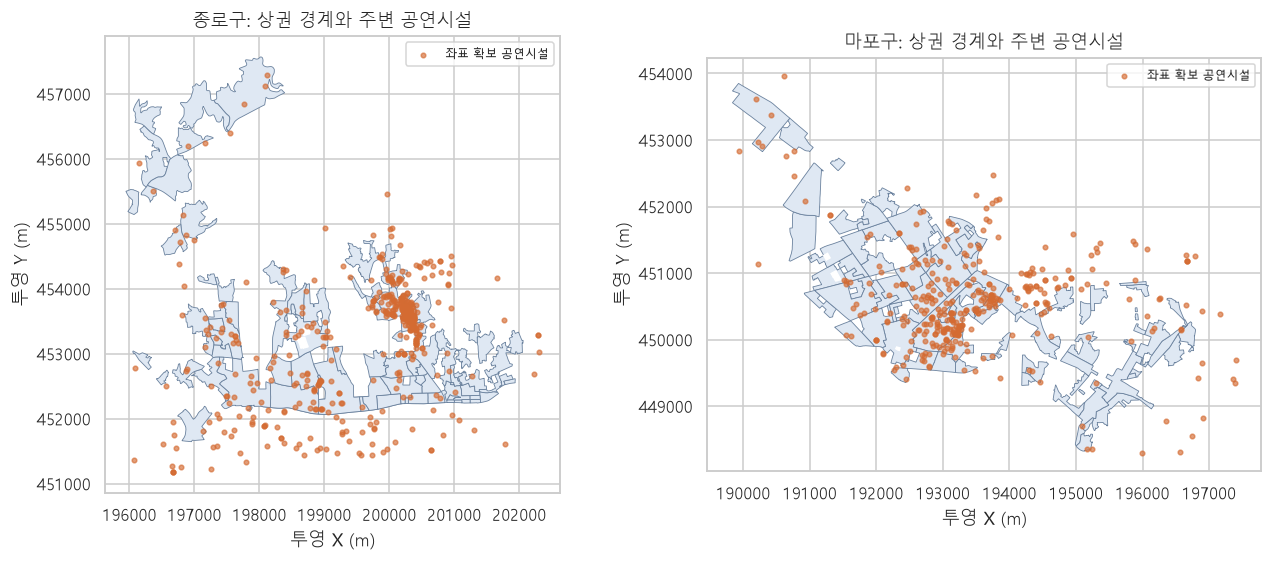

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, district in zip(axes, DISTRICTS.values()):
    subset = [area for area in area_geometries if area['district'] == district]
    ids = {area['area_id'] for area in subset}
    for area in subset:
        geometry = area['geometry']
        polygons = [geometry] if geometry.geom_type == 'Polygon' else list(geometry.geoms)
        for polygon in polygons:
            x, y = polygon.exterior.xy
            ax.fill(x, y, color='#dfe8f3', edgecolor='#6b829e', linewidth=0.55)
            for ring in polygon.interiors:
                x, y = ring.xy
                ax.fill(x, y, color='white')
    nearby_ids = links.loc[links['area_id'].isin(ids), 'mt10id'].unique()
    located = geo_facilities.loc[geo_facilities['mt10id'].isin(nearby_ids)]
    ax.scatter(located['x'], located['y'], s=9, color='#d46b32', alpha=0.65, label='좌표 확보 공연시설')
    ax.set_title(f'{district}: 상권 경계와 주변 공연시설')
    ax.set_aspect('equal'); ax.set_xlabel('투영 X (m)'); ax.set_ylabel('투영 Y (m)')
    ax.ticklabel_format(style='plain', useOffset=False); ax.legend(loc='best', fontsize=8)
save_figure(fig, '05_venues_and_areas.png')


## 5. 분기별 ‘관측된 등록 공연 수’ 만들기

공연 기간과 분기가 하루라도 겹치면 해당 분기에 공연 ID를 포함합니다. 한 상권·분기 안에서는 같은 ID를 한 번만 셉니다. 장기 공연은 여러 분기에 반복됩니다.

`known_performance_count_*m`는 **좌표가 확보되고 연결된 시설에서 관측된 공연 ID 수**입니다. 여기의 0은 관측된 공연이 없다는 뜻이며 실제 공연 0건을 보장하지 않습니다. 공연 기간 중 매일 상연했다고 가정하지 않습니다.


In [8]:
quarter_rows = []
for year in YEARS:
    for number in range(1, 5):
        period = pd.Period(f'{year}Q{number}', freq='Q')
        quarter_rows.append({'quarter': f'{year}{number}', 'start': period.start_time, 'end': period.end_time})
quarter_table = pd.DataFrame(quarter_rows)
usable = performances.loc[performances['valid_coordinates'] & performances['valid_period']].copy()
active_rows = []
for q in quarter_table.itertuples():
    selected = usable.loc[usable['start_date'].le(q.end) & usable['end_date'].ge(q.start),
                          ['mt20id', 'mt10id', 'link_method']].copy()
    selected['quarter'] = q.quarter
    active_rows.append(selected)
active = pd.concat(active_rows, ignore_index=True)
assert not active.duplicated(['mt20id', 'quarter']).any()
active.to_csv(ANALYSIS / 'performance_facility_quarter.csv', index=False, encoding='utf-8-sig')
area_quarters = panel[['area_id', 'quarter']].drop_duplicates().copy()
for radius in [300, 500, 800]:
    near = links.loc[links['distance_m'].le(radius), ['area_id', 'mt10id']]
    nearby_active = active.merge(near, on='mt10id', how='inner', validate='many_to_many')
    counts = nearby_active.groupby(['area_id', 'quarter'], observed=True)['mt20id'].nunique()
    column = f'known_performance_count_{radius}m'
    area_quarters = area_quarters.merge(counts.rename(column), on=['area_id', 'quarter'], how='left', validate='one_to_one')
    # 확보한 시설의 관측 건수 열에만 0을 채웁니다. 매출에는 적용하지 않습니다.
    area_quarters[column] = area_quarters[column].fillna(0).astype(int)
combined = panel.merge(area_quarters, on=['area_id', 'quarter'], how='left', validate='many_to_one')
assert len(combined) == len(panel) and not combined.duplicated(KEY).any()
assert combined.loc[combined['availability'].isin(['sales_absent', 'both_absent']), 'total_sales'].isna().all()
area_quarters.to_csv(ANALYSIS / 'area_performance_quarter.csv', index=False, encoding='utf-8-sig')
combined.to_csv(ANALYSIS / 'performance_sales_panel.csv', index=False, encoding='utf-8-sig')
display(combined[['known_performance_count_300m', 'known_performance_count_500m', 'known_performance_count_800m']].describe())

# 갱신 전 노출과의 차이는 원자료 변경과 구분하여 남깁니다.
baseline_path = ROOT / 'data/analysis/baseline_two_industry/performance_sales_panel.csv'
baseline_sources = json.loads((ROOT / 'final/metadata/validation_sources.json').read_text(encoding='utf-8'))
baseline_record = next(r for r in baseline_sources['files'] if r['path'] == baseline_path.relative_to(ROOT).as_posix())
assert hashlib.sha256(baseline_path.read_bytes()).hexdigest() == baseline_record['sha256']
old_exposure = pd.read_csv(baseline_path, dtype={'area_id': str, 'quarter': str})
exposure_columns = [f'known_performance_count_{radius}m' for radius in [300, 500, 800]]
old_exposure = old_exposure[['area_id', 'quarter', *exposure_columns]].drop_duplicates()
exposure_revision = area_quarters.merge(old_exposure, on=['area_id', 'quarter'],
    suffixes=('_current', '_baseline'), validate='one_to_one')
for column in exposure_columns:
    exposure_revision[column + '_difference'] = exposure_revision[column + '_current'] - exposure_revision[column + '_baseline']
exposure_revision.to_csv(REPORTS / '03_exposure_revisions.csv', index=False, encoding='utf-8-sig')
display(pd.DataFrame([{'radius_m': radius,
    'changed_area_quarters': int(exposure_revision[f'known_performance_count_{radius}m_difference'].ne(0).sum()),
    'largest_increase': int(exposure_revision[f'known_performance_count_{radius}m_difference'].max()),
    'largest_decrease': int(exposure_revision[f'known_performance_count_{radius}m_difference'].min())}
    for radius in [300, 500, 800]]))


,known_performance_count_300m,known_performance_count_500m,known_performance_count_800m
count,"3,624.000","3,624.000","3,624.000"
mean,27.389,57.039,106.742
std,63.061,94.660,129.993
min,0.000,0.000,0.000
25%,0.000,1.000,13.000
50%,3.000,15.000,46.000
75%,23.000,59.000,163.250
max,586.000,627.000,675.000


,radius_m,changed_area_quarters,largest_increase,largest_decrease
0,300,164,33,0
1,500,231,33,0
2,800,395,34,0


## 6. 입력 이력과 연결 한계 저장

원자료 해시를 다시 확인하고 연결 범위·공식 ID·이름 임시 연결·좌표 상태를 저장한다. 이전 두 업종 기준선의 노출 차이는 재수집 정보 반영에 따른 차이로 해석한다.

In [9]:
summary = {'created_utc': datetime.now(timezone.utc).isoformat(),
           'collection_run_id': collection_snapshot['run_id'] if collection_snapshot else None,
           'collection_status': collection_snapshot['status'] if collection_snapshot else 'legacy_processed',
           'source_files': source_provenance,
           'facility_detail_rows': len(facility_details), 'performance_detail_rows': len(performance_details),
           'coordinate_reference_system': 'EPSG:5181',
           'distance_definition': 'minimum_Euclidean_distance_from_facility_point_to_current_area_polygon',
           'performance_period_source': 'stored_2023_2025_monthly_list_not_latest_detail_dates',
           'performance_candidate_ids': len(candidate_ids),
           'performance_candidate_pending': len(candidate_ids - detail_ids),
           'official_link_share_pct': float(official.mean() * 100),
           'target_performance_ids': len(target_linkage),
           'target_official_link_ids': target_official_ids,
           'name_official_conflict_ids': int(performances['name_official_conflict'].sum()),
           'list_detail_period_difference_ids': int(period_comparison['period_differs'].sum()),
           'list_detail_quarter_membership_difference_ids': int(period_comparison['quarter_membership_differs'].sum()),
           'network_requests': 0,
           'performance_ids': len(performances), 'official_link_ids': int(official.sum()),
           'performance_ids_with_coordinates': int(performances['valid_coordinates'].sum()),
           'unresolved_performance_ids': len(unresolved), 'venue_area_relations': len(links),
           'changed_500m_area_quarters': int(exposure_revision['known_performance_count_500m_difference'].ne(0).sum()),
           'provisional_name_link_ids': int(performances['link_method'].isin(['exact_unique_name', 'prefix_unique_name']).sum()),
           'panel_rows': len(combined), 'estimated_models': 0,
           'facility_ids_with_coordinates': int(facilities['valid_coordinates'].sum()),
           'facility_ids_without_coordinates': int((~facilities['valid_coordinates']).sum()),
           'classification': 'linkage_preparation_with_provisional_links_and_unverified_historical_locations'}
pd.DataFrame(source_provenance).to_csv(REPORTS / '03_input_sources.csv', index=False, encoding='utf-8-sig')
for record in source_provenance:
    assert hashlib.sha256((ROOT / record['path']).read_bytes()).hexdigest() == record['sha256']
(REPORTS / 'linkage_analysis_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
display(Markdown(f"**해석 범위:** 공연 {len(performances):,}개 중 좌표 연결 가능 {summary['performance_ids_with_coordinates']:,}개, "
                 f"공식 상세 ID 직접 확인 {summary['official_link_ids']:,}개({summary['official_link_share_pct']:.2f}%), 이름 임시 연결 {summary['provisional_name_link_ids']:,}개입니다. "
                 f"상세 수집 후보 {len(candidate_ids):,}개 중 미확보 {len(candidate_ids - detail_ids):,}개이며, 후보 완료가 전체 목록의 공식 연결 완료를 뜻하지는 않습니다. "
                 '좌표 확보는 현재 시설 목록 기준입니다. 이름 임시 연결의 공식 ID 검증과 과거 시설 위치·경계 검증이 남아 있으므로 인과효과로 확정하지 않습니다.'))


**해석 범위:** 공연 30,047개 중 좌표 연결 가능 30,047개, 공식 상세 ID 직접 확인 13,727개(45.69%), 이름 임시 연결 16,320개입니다. 상세 수집 후보 13,727개 중 미확보 0개이며, 후보 완료가 전체 목록의 공식 연결 완료를 뜻하지는 않습니다. 좌표 확보는 현재 시설 목록 기준입니다. 이름 임시 연결의 공식 ID 검증과 과거 시설 위치·경계 검증이 남아 있으므로 인과효과로 확정하지 않습니다.